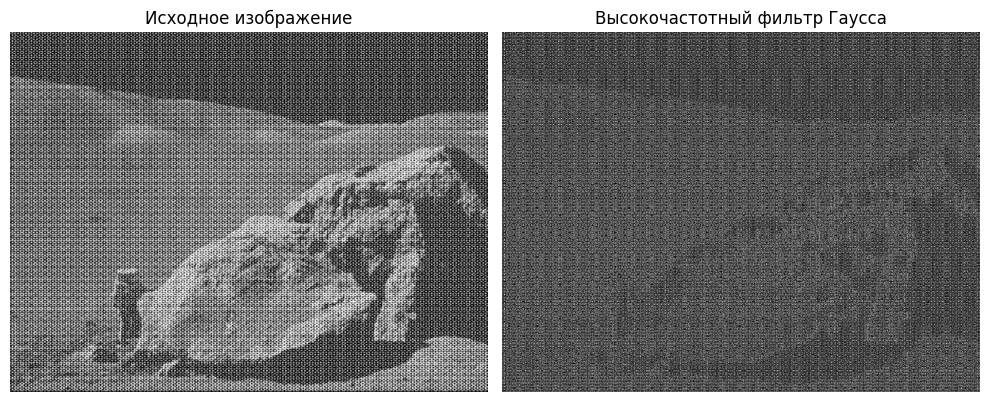

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

u = np.arange(rows)
v = np.arange(cols)
v_grid, u_grid = np.meshgrid(v, u)

d_squared = (u_grid - crow)**2 + (v_grid - ccol)**2
d_0 = 30.0

ghpf = 1.0 - np.exp(-d_squared / (2.0 * (d_0**2)))
mask = np.repeat(ghpf[:, :, np.newaxis], 2, axis=2)

fshift = dft_shift * mask
f_ishift = np.fft.ifftshift(fshift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])
cv.normalize(img_back, img_back, 0, 255, cv.NORM_MINMAX)
img_back = np.uint8(img_back)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(122)
plt.imshow(img_back, cmap='gray')
plt.title('Высокочастотный фильтр Гаусса')
plt.axis('off')
plt.tight_layout()
plt.show()

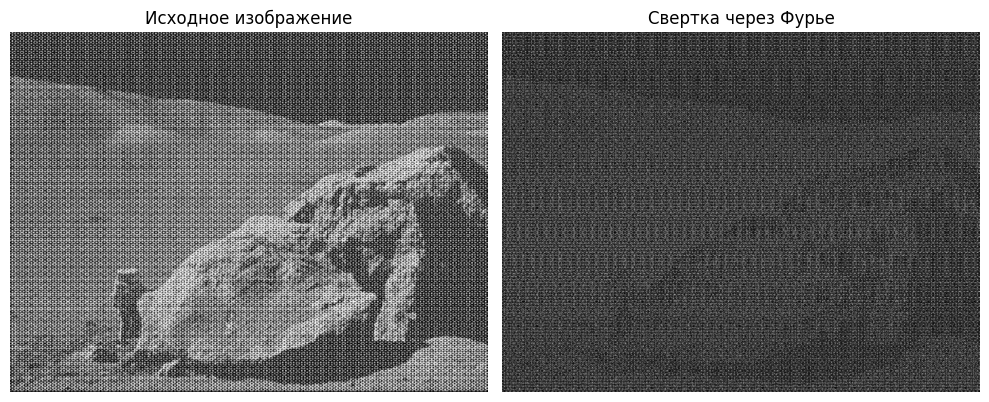

In [3]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

kernel = np.array([[-1, -1, -1],
                   [-1,  8, -1],
                   [-1, -1, -1]], dtype=np.float32)

img_h, img_w = img.shape
k_h, k_w = kernel.shape

pad_h = img_h + k_h - 1
pad_w = img_w + k_w - 1

opt_h = cv.getOptimalDFTSize(pad_h)
opt_w = cv.getOptimalDFTSize(pad_w)

padded_img = np.zeros((opt_h, opt_w), dtype=np.float32)
padded_img[:img_h, :img_w] = img

padded_kernel = np.zeros((opt_h, opt_w), dtype=np.float32)
padded_kernel[:k_h, :k_w] = kernel

dft_img = cv.dft(padded_img, flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(padded_kernel, flags=cv.DFT_COMPLEX_OUTPUT)

mul_re = dft_img[:, :, 0] * dft_kernel[:, :, 0] - dft_img[:, :, 1] * dft_kernel[:, :, 1]
mul_im = dft_img[:, :, 0] * dft_kernel[:, :, 1] + dft_img[:, :, 1] * dft_kernel[:, :, 0]
dft_res = np.stack([mul_re, mul_im], axis=-1)

idft_res = cv.idft(dft_res, flags=cv.DFT_SCALE)
conv_full = idft_res[:, :, 0]

start_y = (k_h - 1) // 2
start_x = (k_w - 1) // 2
conv_cropped = conv_full[start_y:start_y + img_h, start_x:start_x + img_w]

conv_display = cv.normalize(np.abs(conv_cropped), None, 0, 255, cv.NORM_MINMAX)
conv_display = np.uint8(conv_display)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(122)
plt.imshow(conv_display, cmap='gray')
plt.title('Свертка через Фурье')
plt.axis('off')
plt.tight_layout()
plt.show()

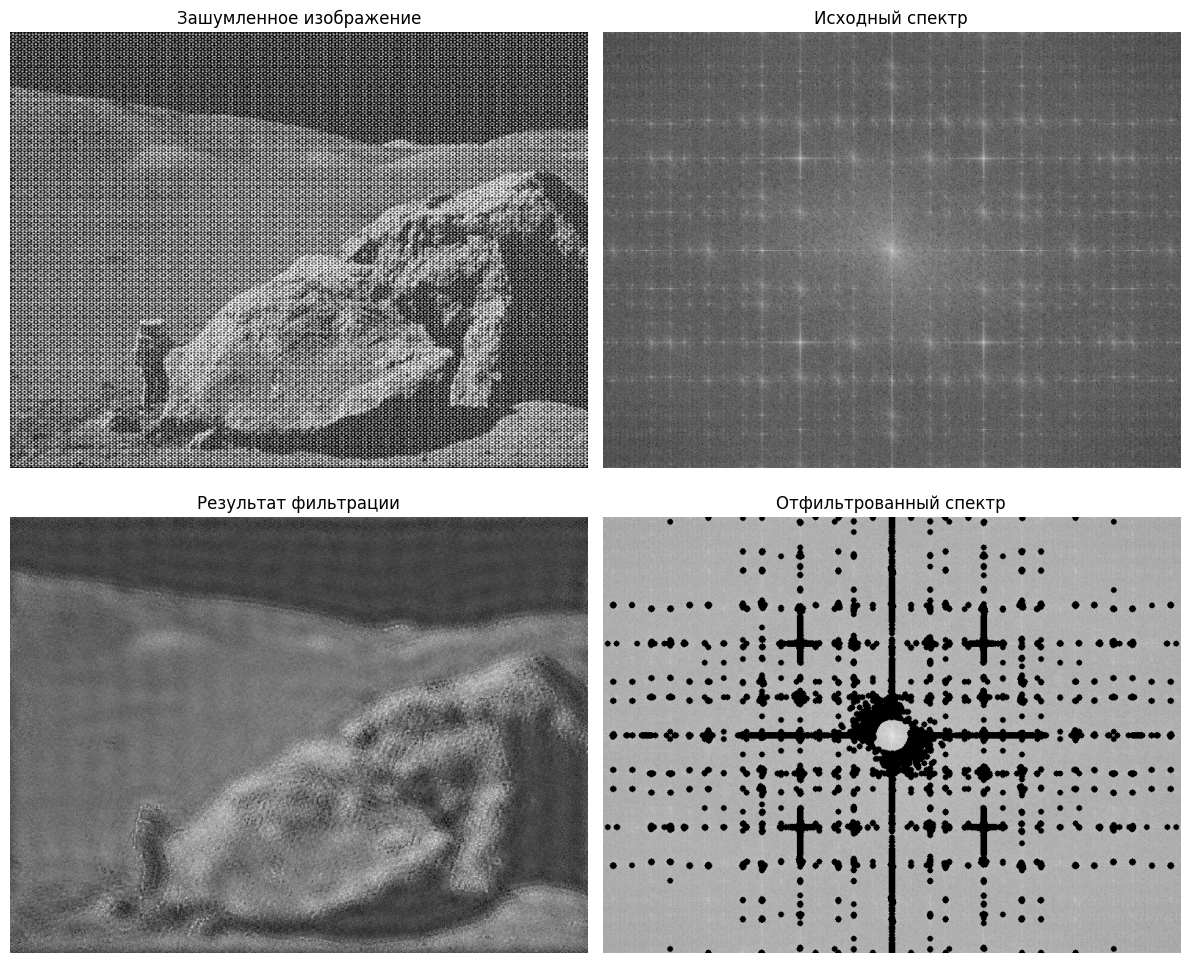

In [4]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

mag = cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])
spectrum = 20 * np.log(mag + 1e-5)

center_exclude_radius = 25
u = np.arange(rows)
v = np.arange(cols)
v_grid, u_grid = np.meshgrid(v, u)
center_dist = np.sqrt((u_grid - crow)**2 + (v_grid - ccol)**2)

spectrum_masked = spectrum.copy()
spectrum_masked[center_dist < center_exclude_radius] = 0

threshold = np.mean(spectrum_masked[spectrum_masked > 0]) + 2.5 * np.std(spectrum_masked[spectrum_masked > 0])
noise_peaks = (spectrum_masked > threshold)

notch_mask = np.ones((rows, cols), dtype=np.float32)
peak_coords = np.argwhere(noise_peaks)

notch_radius = 4
for py, px in peak_coords:
    cv.circle(notch_mask, (px, py), notch_radius, 0, -1)

filter_mask = np.repeat(notch_mask[:, :, np.newaxis], 2, axis=2)
fshift_filtered = dft_shift * filter_mask

f_ishift = np.fft.ifftshift(fshift_filtered)
img_restored = cv.idft(f_ishift)
img_restored = cv.magnitude(img_restored[:, :, 0], img_restored[:, :, 1])
cv.normalize(img_restored, img_restored, 0, 255, cv.NORM_MINMAX)
img_restored = np.uint8(img_restored)

filtered_mag = cv.magnitude(fshift_filtered[:, :, 0], fshift_filtered[:, :, 1])
filtered_spectrum = 20 * np.log(filtered_mag + 1e-5)

plt.figure(figsize=(12, 10))
plt.subplot(221)
plt.imshow(img, cmap='gray')
plt.title('Зашумленное изображение')
plt.axis('off')

plt.subplot(222)
plt.imshow(spectrum, cmap='gray')
plt.title('Исходный спектр')
plt.axis('off')

plt.subplot(223)
plt.imshow(img_restored, cmap='gray')
plt.title('Результат фильтрации')
plt.axis('off')

plt.subplot(224)
plt.imshow(filtered_spectrum, cmap='gray')
plt.title('Отфильтрованный спектр')
plt.axis('off')

plt.tight_layout()
plt.show()